# 8.11 의사결정트리 깊이와 가지 분기 해석

wine.csv는 178행입니다. scikit-learn 내장 Wine 데이터(load_wine), UCI Wine에서 유래한 178개 관측. 생성 자료 아님. 13개 연속형 화학 분석 특성과 target(0,1,2). 7장은 target==0을 양성으로 재정의한다. 물리 단위는 원 출처 설명을 확인한다.

선정 이유: 작은 Wine 표본과 수치 입력은 얕은 트리의 분기 조건을 직접 따라가기 좋습니다. 같은 검증 행에서 깊이만 바꾸어 구조와 오차의 관계를 확인하기 위해 선택했습니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 의사결정트리 분류기(Decision Tree Classifier), plot_tree 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 정확도(Accuracy) 계산 함수를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

# 가져오기(Import) 문장으로 훈련 평가 분리 함수(Train Test Split)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.model_selection import train_test_split

# 가져오기(Import) 문장으로 의사결정트리 분류기(Decision Tree Classifier), plot_tree 기능를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.tree import DecisionTreeClassifier,plot_tree

# 가져오기(Import) 문장으로 정확도(Accuracy) 계산 함수를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from sklearn.metrics import accuracy_score

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"sec_11_tree_depth"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.

입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

목표값(Target, y)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.

변수 rows를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for depth in [1,2,3,4,6,None]:에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.

변수 r를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 r.to_csv(OUT/"tree_depth.csv",index=False) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

In [5]:
# 쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.
f=pd.read_csv(DATA/"wine.csv")

# 입력 특성 행렬(Feature Matrix, X)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
X=f.drop(columns="target")

# 목표값(Target, y)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
y=f.target

# 훈련 평가 분리(Train Test Split)를 수행합니다. 행 번호 두 배열이면 앞은 훈련, 뒤는 평가이며 네 배열이면 입력과 목표의 행 대응을 유지합니다. test_size는 평가 비율이고 stratify는 클래스 비율 유지 조건입니다.
tr,va=train_test_split(np.arange(len(f)),test_size=.3,stratify=y,random_state=42)

# 변수 rows를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
rows=[]

# 반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for depth in [1,2,3,4,6,None]:에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.
for depth in [1,2,3,4,6,None]:
    m=DecisionTreeClassifier(max_depth=depth,random_state=42)
    m.fit(X.iloc[tr],y.iloc[tr])
    rows.append({"depth_label":str(depth),"nodes":m.tree_.node_count,
        "train_accuracy":accuracy_score(y.iloc[tr],m.predict(X.iloc[tr])),
        "validation_accuracy":accuracy_score(y.iloc[va],m.predict(X.iloc[va]))})

# 변수 r를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
r=pd.DataFrame(rows)

# 앞 셀의 값을 사용해 r.to_csv(OUT/"tree_depth.csv",index=False) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
r.to_csv(OUT/"tree_depth.csv",index=False)

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.plot(range(len(r)),r.train_accuracy,"ko-",label="Train")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.plot(range(len(r)),r.validation_accuracy,"ks--",label="Validation")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.xticks(range(len(r)),r.depth_label)

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.ylim(0,1.03)

Out[0]: (0.0, 1.03)


## 셀 6 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

변수 small를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

앞 셀의 값을 사용해 plot_tree(small,feature_names=X.columns,class_names=["0","1","2"], 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

{
  "validation_n": 54,
  "comparison": [
    {
      "depth_label": "1",
      "nodes": 3,
      "train_accuracy": 0.6612903225806451,
      "validation_accuracy": 0.6111111111111112
    },
    {
      "depth_label": "2",
      "nodes": 7,
      "train_accuracy": 0.9354838709677419,
      "validation_accuracy": 0.8888888888888888
    },
    {
      "depth_label": "3",
      "nodes": 13,
      "train_accuracy": 0.9919354838709677,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "depth_label": "4",
      "nodes": 15,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "depth_label": "6",
      "nodes": 15,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    },
    {
      "depth_label": "None",
      "nodes": 15,
      "train_accuracy": 1.0,
      "validation_accuracy": 0.9629629629629629
    }
  ]
}


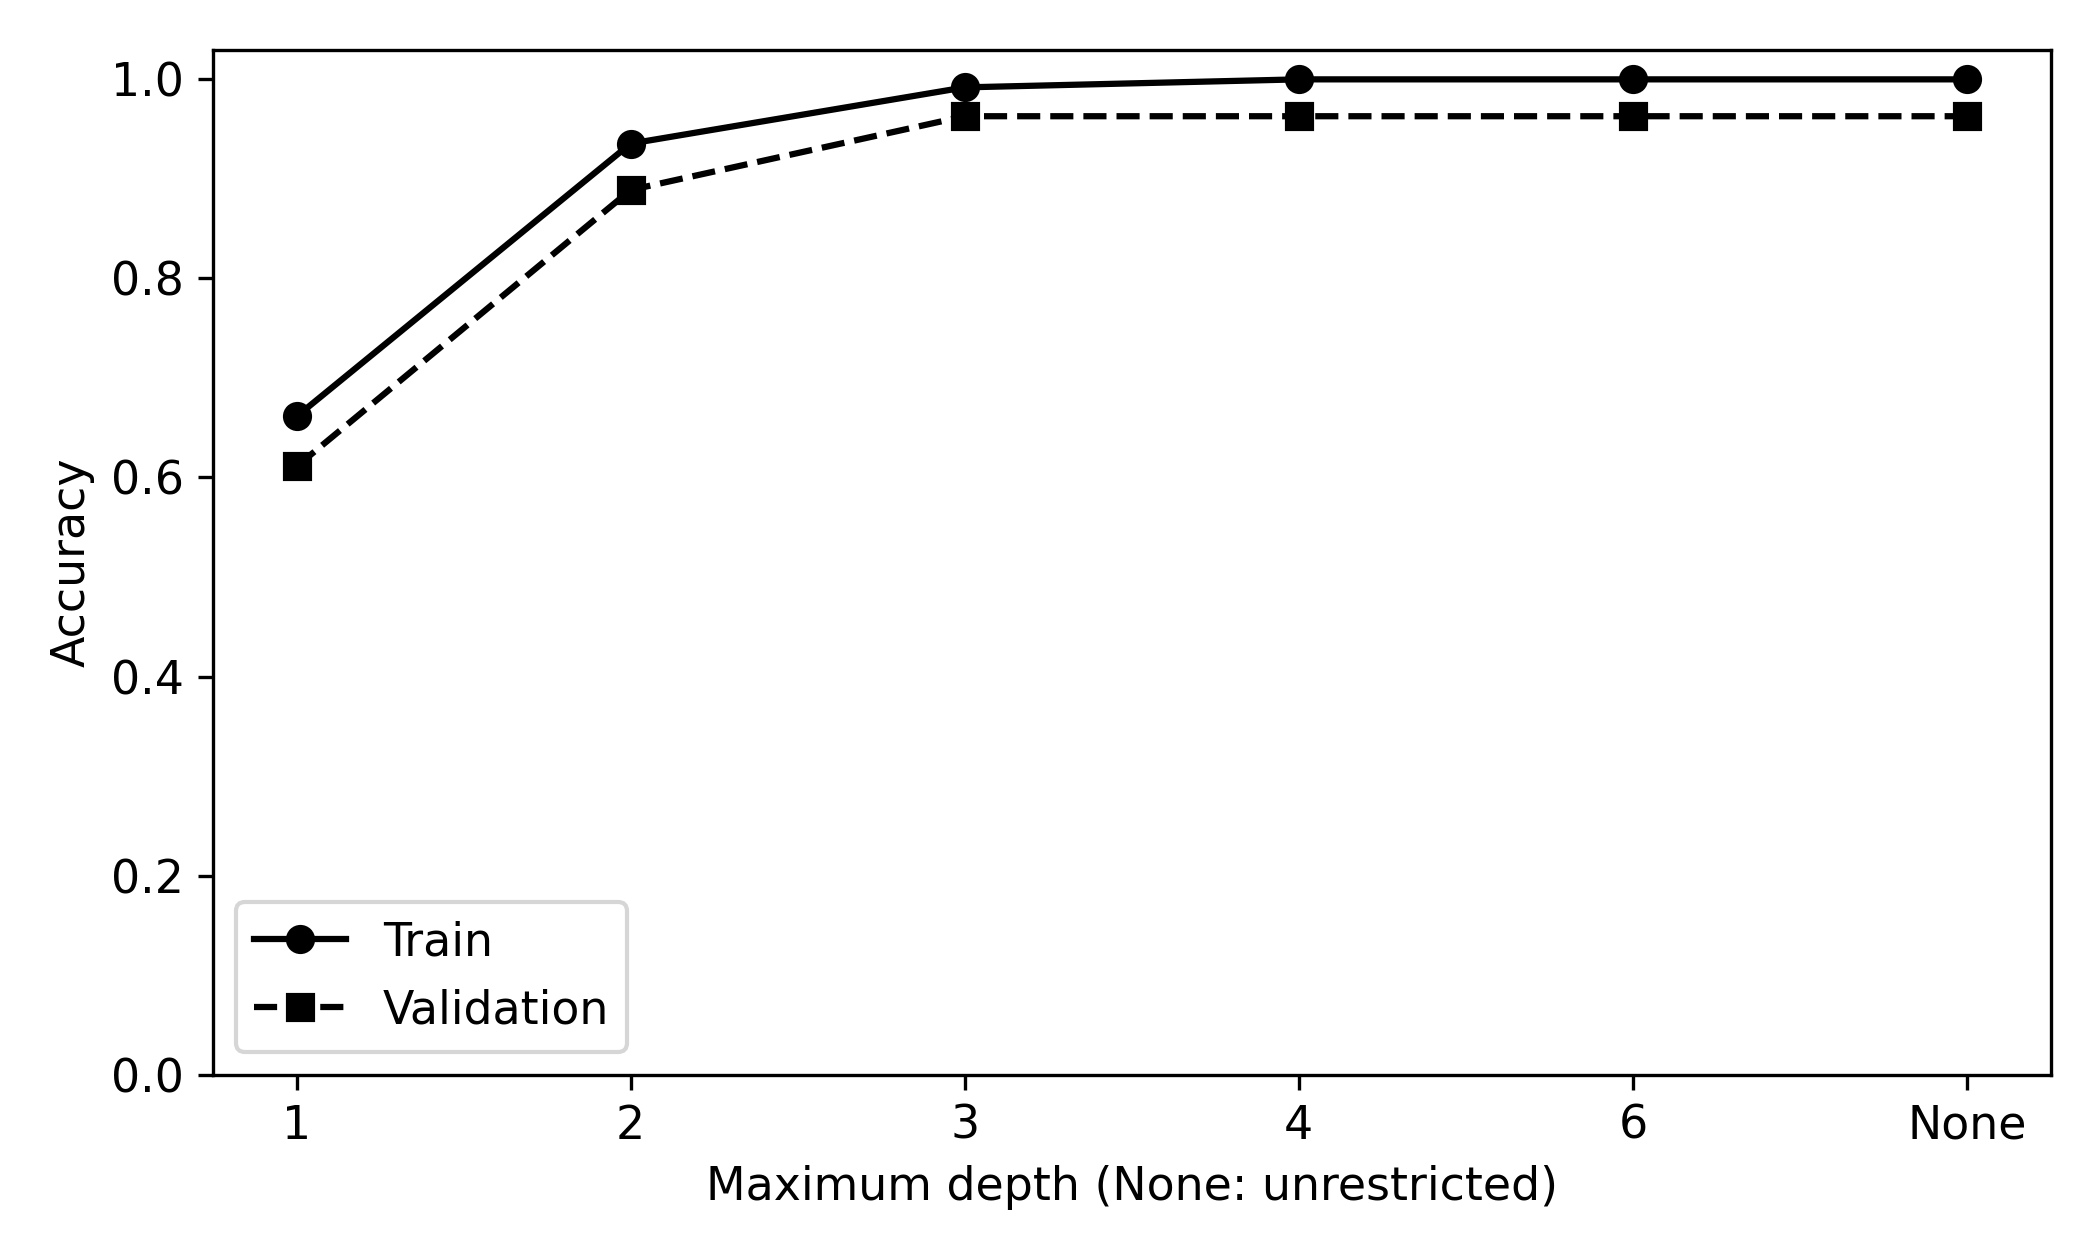

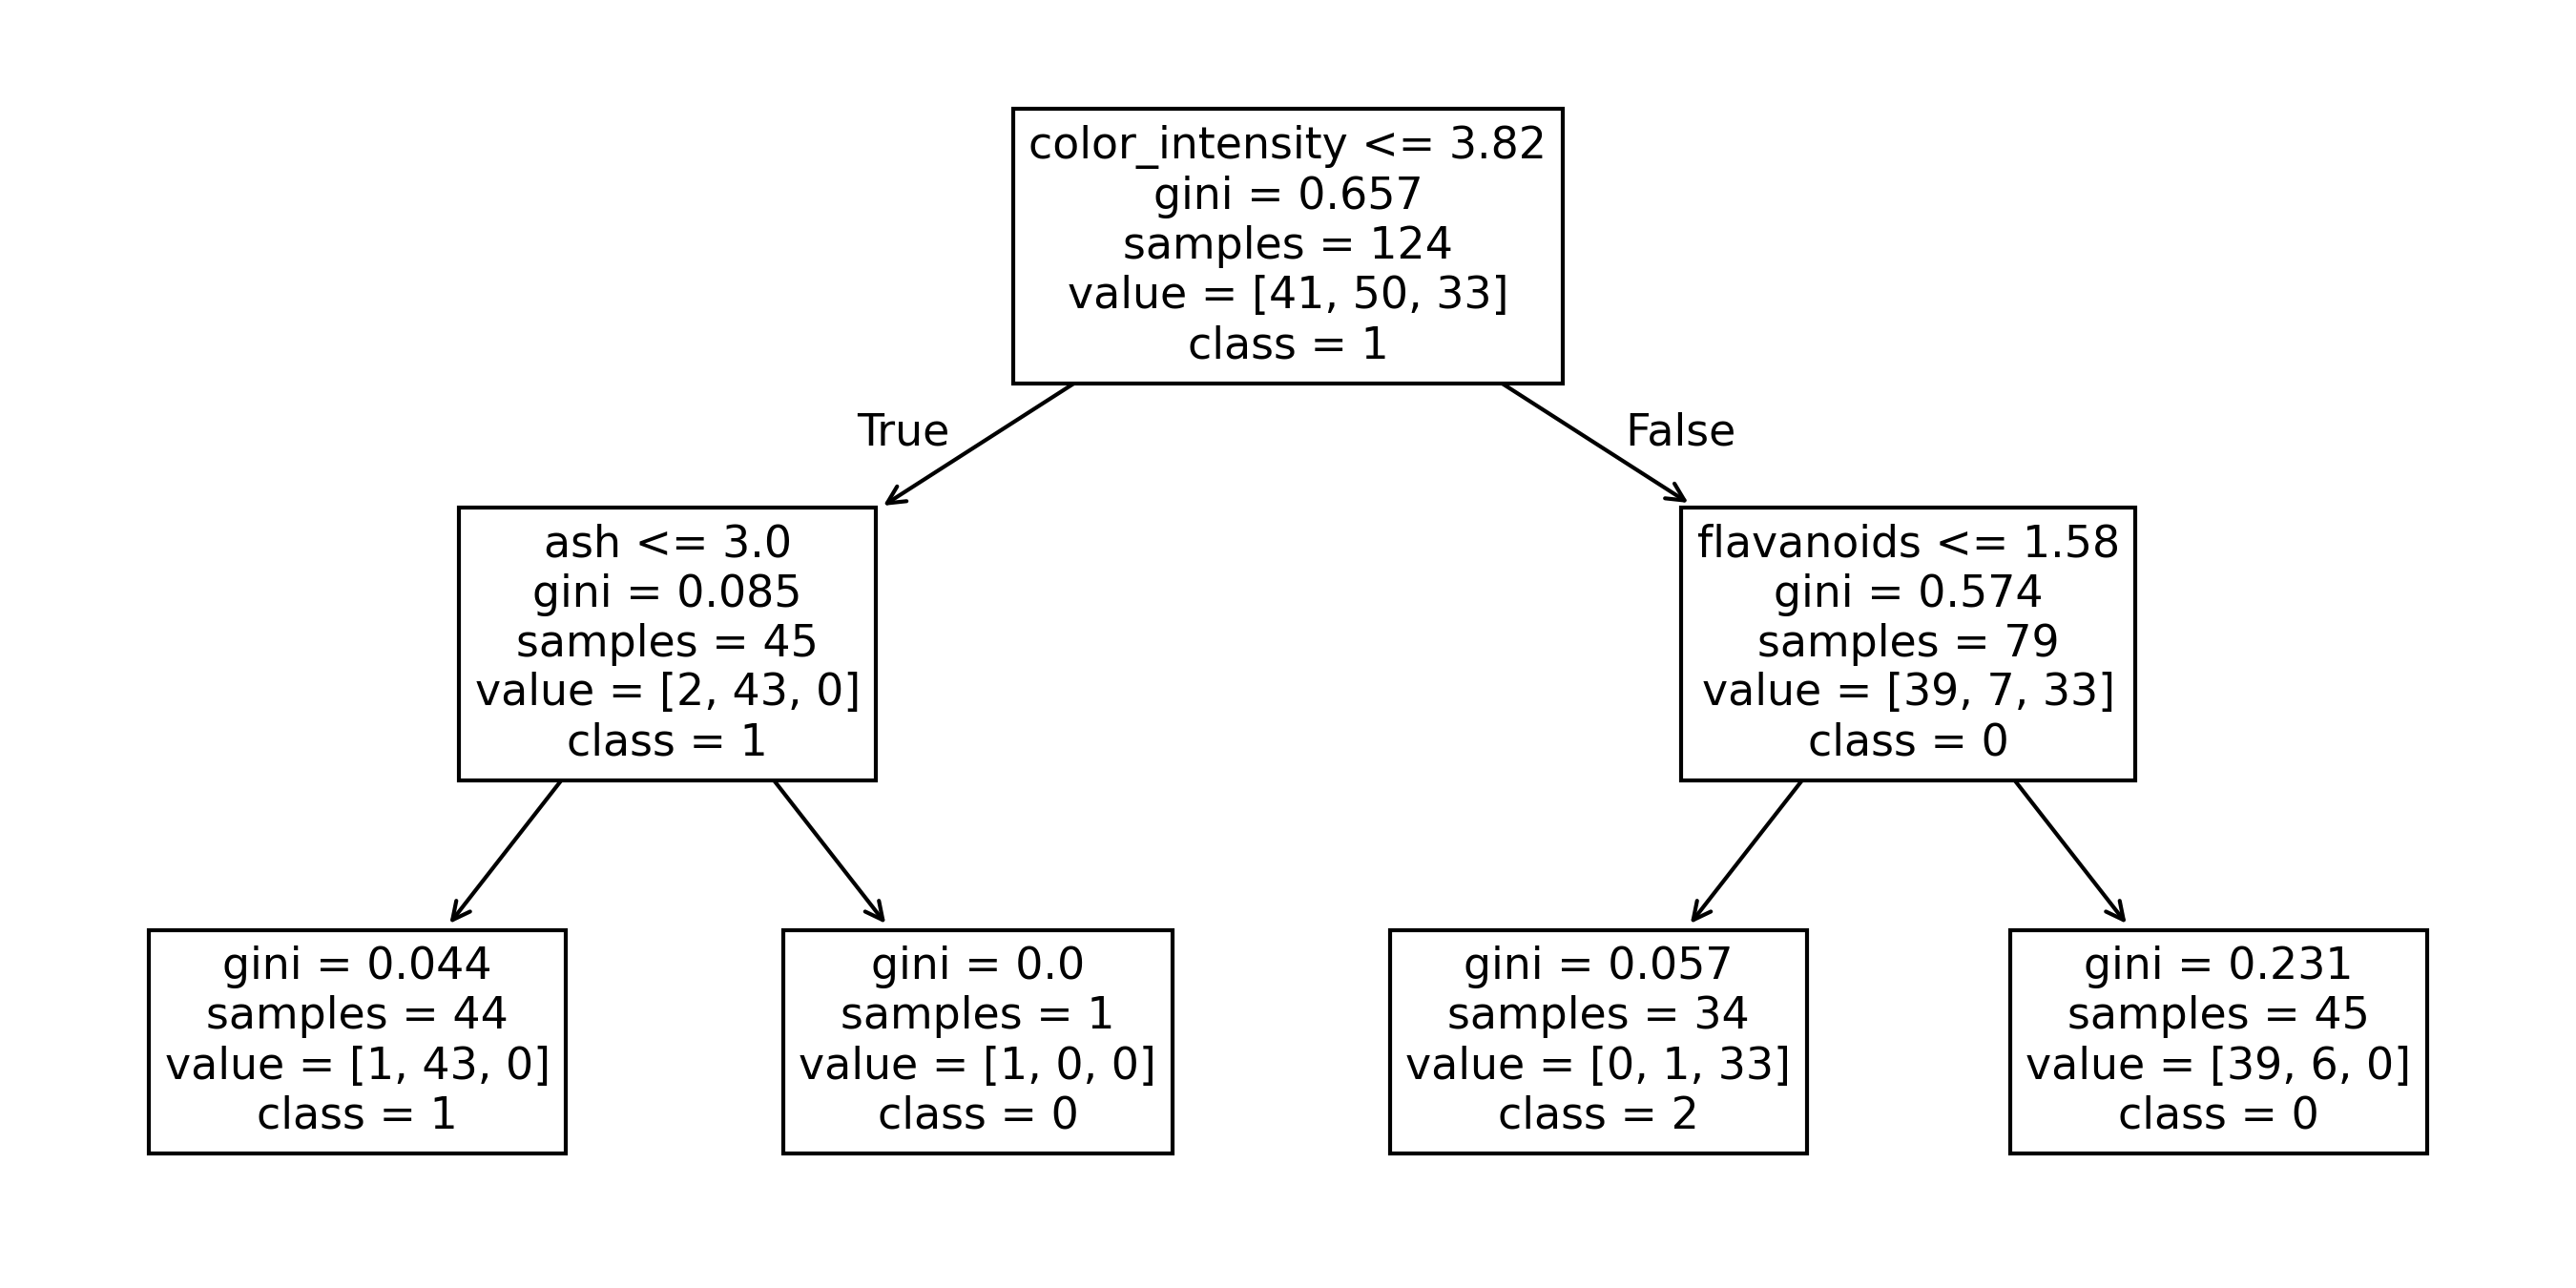

In [6]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.xlabel("Maximum depth (None: unrestricted)")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.ylabel("Accuracy")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.legend()

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"tree_depth")

# 변수 small를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
small=DecisionTreeClassifier(max_depth=2,random_state=42).fit(X.iloc[tr],y.iloc[tr])

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
plt.figure(figsize=(9,4.5))

# 앞 셀의 값을 사용해 plot_tree(small,feature_names=X.columns,class_names=["0","1","2"], 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
plot_tree(small,feature_names=X.columns,class_names=["0","1","2"],
    filled=False,rounded=False,fontsize=11,impurity=True)

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"tree_structure")

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"tree_depth",{"validation_n":len(va),"comparison":rows})

## 그림과 결과 해석

구조 그림은 깊이 2의 별도 트리다. 조건이 참이면 왼쪽 자식, 거짓이면 오른쪽 자식으로 내려간다. value는 해당 훈련 노드의 클래스 분포다.

깊이 비교는 검증을 통한 모델 선택이다. 노드의 훈련 분포가 새로운 모집단의 확률을 그대로 의미하지는 않는다.